In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time

In [2]:
filename = "damage_data9.csv"
df = pd.read_csv(filename, header=0, sep=',')
#print('Are ther any Nan value?:\n', np.isnan(df).any())
# ignore rows which contain zero
# ignore_zero = df[(df['Strain']==0) | (df['Stress']==0) | (df['Temp']==0) | (df['Rate']==0)]
#df=pd.concat([df, ignore_zero, ignore_zero]).drop_duplicates(keep=False)
df.head()

,Disp,Force,Geom,D1,D2,D3,D4
0,1.91105,8.92105,1,1.00,1.99,1.28,2.41
1,1.71835,9.13433,1,1.22,2.68,0.10,1.27
2,2.38966,7.36185,1,2.29,1.77,2.35,0.81
3,2.06188,8.62037,1,2.31,1.79,0.33,0.99
4,2.27274,7.94911,1,2.90,0.17,0.66,0.89


## Preprocessing

In [3]:
from sklearn.preprocessing import MinMaxScaler

In [5]:
scaler = MinMaxScaler()
#df1 = df.drop(columns=['Label'])
scaler.fit(df)

MinMaxScaler()

In [6]:
data_scaled = scaler.transform(df)

In [7]:
data_scaled = pd.DataFrame(data_scaled)

In [8]:
data_scaled.columns = ['Disp', 'Force', 'Geom', 'D1', 'D2', 'D3', 'D4']

In [9]:
#data_scaled['Label'] = df['Label']

In [10]:
data_scaled

,Disp,Force,Geom,D1,D2,D3,D4
0,0.725116,0.854415,0.0,0.337979,0.657439,0.418440,0.810997
1,0.637930,0.885951,0.0,0.414634,0.896194,0.000000,0.419244
2,0.941662,0.623866,0.0,0.787456,0.581315,0.797872,0.261168
3,0.793359,0.809955,0.0,0.794425,0.588235,0.081560,0.323024
4,0.888762,0.710700,0.0,1.000000,0.027682,0.198582,0.288660
...,...,...,...,...,...,...,...
175,0.770302,0.081684,1.0,0.337979,0.003460,0.283688,0.017182
176,0.770302,0.081684,1.0,0.337979,0.072664,0.283688,0.017182
177,0.631311,0.067377,1.0,0.825784,0.453287,0.212766,0.017182
178,0.631311,0.067377,1.0,0.825784,0.003460,0.212766,0.360825


## Preprocessing 2

In [11]:
df.columns

Index(['Disp', 'Force', 'Geom', 'D1', 'D2', 'D3', 'D4'], dtype='object')

In [14]:
df['Force'].max()

9.90564

In [15]:
# apply scaling
df_scaled = pd.DataFrame()
disp_range = np.array([0.3, 2.6])
force_range = np.array([3, 10])
s_max_range = np.array([821.064, 2669.76])
s_mid_range = np.array([53.9087, 1678.56]) 
s_min_range = np.array([8.36831, 1104.41])
peeq_range = np.array([0.0656731, 1.92155])
triax_range = np.array([-0.234595, 2.20036])
lode_range = np.array([0.00560415, 0.986])
geom_range = np.array([1,5])
d1_range = np.array([0.03, 2.9])
d2_range = np.array([0.09, 2.98])
d3_range = np.array([0.1, 2.92])
d4_range = np.array([0.05, 2.96])


def manual_scaling(feat, range_value):
    return (feat - range_value[0])/(range_value[1] - range_value[0])
def manual_descaling(feat, range_value): # inverse of the function above
    return (feat * (range_value[1] - range_value[0])) + range_value[0]

#col_ranges = {'Disp': disp_range,
#              'Force': force_range,
#              'S_max': s_max_range,
#              'S_mid': s_mid_range,
#              'S_min': s_min_range,
#              'Peeq': peeq_range,
#              'Triax': triax_range,
#              'Lode': lode_range,
#              'D1': d1_range,
#              'D2': d2_range,
#              'D3': d3_range,
#              'D4': d4_range}

col_ranges = {'Disp': disp_range,
              'Force': force_range,
              'Geom': geom_range,
              'D1': d1_range,
              'D2': d2_range,
              'D3': d3_range,
              'D4': d4_range}

inp_col_ranges = {'Disp': disp_range,
              'Force': force_range,
              'Geom': geom_range }

for column, col_range in col_ranges.items():
    df_scaled[column] = manual_scaling(df[column], col_range)
    
df_scaled.head()

,Disp,Force,Geom,D1,D2,D3,D4
0,0.700457,0.845864,0.0,0.337979,0.657439,0.418440,0.810997
1,0.616674,0.876333,0.0,0.414634,0.896194,0.000000,0.419244
2,0.908548,0.623121,0.0,0.787456,0.581315,0.797872,0.261168
3,0.766035,0.802910,0.0,0.794425,0.588235,0.081560,0.323024
4,0.857713,0.707016,0.0,1.000000,0.027682,0.198582,0.288660


In [16]:
out_col_ranges = {'D1': d1_range,
              'D2': d2_range,
              'D3': d3_range,
              'D4': d4_range}

In [17]:
df_scaled

,Disp,Force,Geom,D1,D2,D3,D4
0,0.700457,0.845864,0.0,0.337979,0.657439,0.418440,0.810997
1,0.616674,0.876333,0.0,0.414634,0.896194,0.000000,0.419244
2,0.908548,0.623121,0.0,0.787456,0.581315,0.797872,0.261168
3,0.766035,0.802910,0.0,0.794425,0.588235,0.081560,0.323024
4,0.857713,0.707016,0.0,1.000000,0.027682,0.198582,0.288660
...,...,...,...,...,...,...,...
175,0.743878,0.099299,1.0,0.337979,0.003460,0.283688,0.017182
176,0.743878,0.099299,1.0,0.337979,0.072664,0.283688,0.017182
177,0.610313,0.085476,1.0,0.825784,0.453287,0.212766,0.017182
178,0.610313,0.085476,1.0,0.825784,0.003460,0.212766,0.360825


## Decompose features and labels

In [18]:
#feature_columns = ['Disp', 'Force', 'S_max', 'S_mid', 'S_min', 'Peeq', 'Triax', 'Lode']
feature_columns = ['Disp', 'Force', 'Geom']
label_columns = ['D1', 'D2', 'D3', 'D4']

df_features = pd.DataFrame()
df_labels = pd.DataFrame()

for col in feature_columns:
    df_features[col] = df_scaled[col]
    
for col in label_columns:
    df_labels[col] = df_scaled[col]

In [19]:
X = df_features.to_numpy()
y = df_labels.to_numpy()

In [20]:
print(X.shape)
print(y.shape)

(180, 3)
(180, 4)


## Decompose train and test set

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=96, test_size=0.1)

In [23]:
print(X_train.shape)
print(X_test.shape)

(162, 3)
(18, 3)


## ANN

In [24]:
from keras.layers import Dense
from keras.models import Sequential
from keras.wrappers.scikit_learn import KerasRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from scipy import stats
from scipy.stats import randint as sp_randint

In [25]:
# utility function to report best scores
def report(results, n_top=3):
    for i in range(1, n_top + 1):
        candidates = np.flatnonzero(results['rank_test_score'] == i)
        for candidate in candidates:
            print("Model with rank: {0}".format(i))
            print("Mean validation score: {0:.3f} (std: {1:.3f})".format(
                  results['mean_test_score'][candidate],
                  results['std_test_score'][candidate]))
            print("Parameters: {0}".format(results['params'][candidate]))
            print("")

In [26]:
def ANNmodel(hid_layers=[], in_dim=1, out_dim=4):
    model = Sequential()
    if len(hid_layers) == 0:
        model.add(Dense(out_dim, input_dim=in_dim, activation='relu', kernel_initializer='normal'))
    elif len(hid_layers) == 1:
        model.add(Dense(in_dim, input_dim=in_dim, activation='relu', 
                        kernel_initializer='normal'))
        model.add(Dense(out_dim))
    else:
        model.add(Dense(hid_layers[0], input_dim=in_dim, activation='relu', 
                        kernel_initializer='normal'))
        for layer in hid_layers[1:]:
            model.add(Dense(layer, activation='relu'))
        model.add(Dense(out_dim))
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model

def get_hid_layers(min_layers=0, max_layers=5, min_neurons=1, max_neurons=10, n_iter=1):
    hid_layers = []
    for _ in range(n_iter):
        layers = np.random.randint(min_layers, max_layers)
        hid_layers.append(np.random.randint(low=min_neurons, high=max_neurons, size=layers).tolist())
    return hid_layers

In [27]:
#train
runANN = True
np.random.seed(99)
n_iter = 50
param_dist = {'hid_layers': get_hid_layers(max_layers=6, min_neurons=1, 
                                           max_neurons=20, n_iter=n_iter)}

if runANN:
    ann = KerasRegressor(build_fn=ANNmodel, in_dim=X_train.shape[1], 
                         epochs=200, batch_size=16, verbose=0)
    random_search_ann = GridSearchCV(estimator=ann, param_grid=param_dist, 
                                     scoring='neg_mean_squared_error')
    start = time.time()
    random_search_ann.fit(X_train, y_train)
    elapsed_ann = (time.time() - start)
    print("RandomizedSearchCV took %.2f seconds for %d candidates"
          " parameter settings." % (elapsed_ann, n_iter))
    report(random_search_ann.cv_results_)

C:\Users\prasads1\AppData\Local\Temp\ipykernel_20040\3245571362.py:9: DeprecationWarning: KerasRegressor is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  ann = KerasRegressor(build_fn=ANNmodel, in_dim=X_train.shape[1],


RandomizedSearchCV took 376.84 seconds for 50 candidates parameter settings.
Model with rank: 1
Mean validation score: -0.054 (std: 0.007)
Parameters: {'hid_layers': [18, 14, 17, 19]}

Model with rank: 2
Mean validation score: -0.054 (std: 0.006)
Parameters: {'hid_layers': [16, 17, 10, 15]}

Model with rank: 3
Mean validation score: -0.055 (std: 0.008)
Parameters: {'hid_layers': [12, 7, 8]}



In [28]:
# test
#runANN = False 
if runANN:
    best_ann = random_search_ann.best_estimator_
else:
    best_ann_param =  {'hid_layers': [18, 14, 17, 19]} 
    best_ann = KerasRegressor(build_fn=ANNmodel, in_dim=X.shape[1],
                              epochs=200, batch_size=8, verbose=0, **best_ann_param)
start = time.time()
best_ann.fit(X, y)
elapsed_ann_test = (time.time() - start)
print('r2_score for training set:', r2_score(y, best_ann.predict(X)))
print("ANN took %.2f seconds for test." % (elapsed_ann_test))

r2_score for training set: 0.16746052648659873
ANN took 1.90 seconds for test.


### Accuracy Test

-7.871723734622883


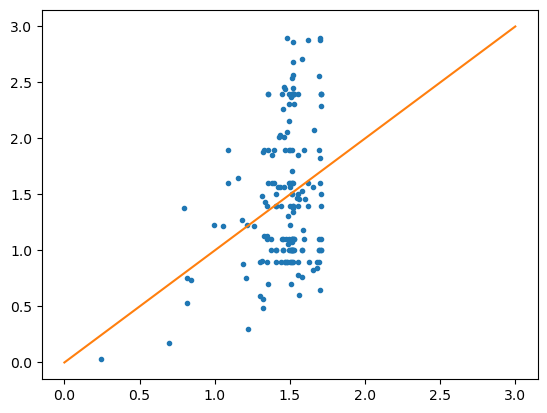

In [30]:
# D1
x_values = np.linspace(0, 3, 10)
y_values = x_values
d1_pred = best_ann.predict(X)[:,0]
plt.plot(manual_descaling(d1_pred, d1_range), manual_descaling(y[:,0], d1_range), '.')
plt.plot(x_values, y_values)
print(r2_score(d1_pred, y[:,0]))

-2.2935346412766524


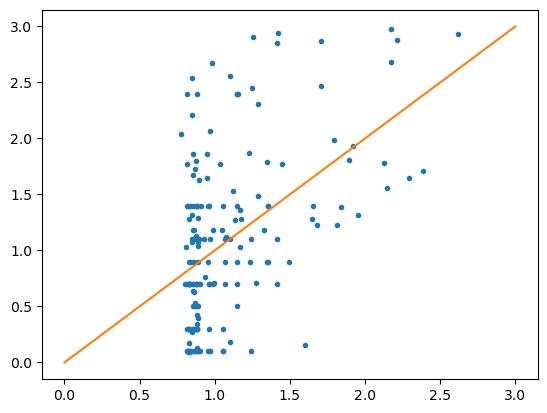

In [31]:
# D2
x_values = np.linspace(0, 3, 10)
y_values = x_values
d2_pred = best_ann.predict(X)[:,1]
plt.plot(manual_descaling(d2_pred, d2_range), manual_descaling(y[:,1], d2_range), '.')
plt.plot(x_values, y_values)
print(r2_score(d2_pred, y[:,1]))

-23.388195870430426


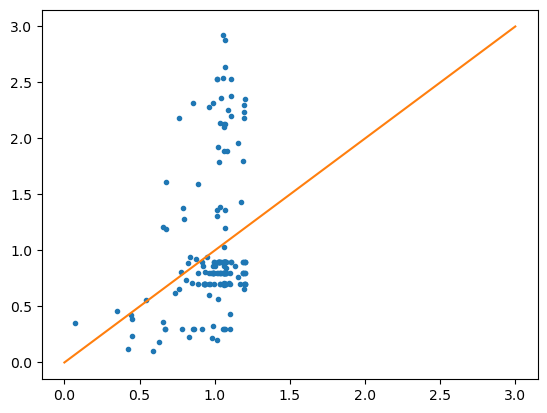

In [32]:
# D3
x_values = np.linspace(0, 3, 10)
y_values = x_values
d3_pred = best_ann.predict(X)[:,2]
plt.plot(manual_descaling(d3_pred, d3_range), manual_descaling(y[:,2], d3_range), '.')
plt.plot(x_values, y_values)
print(r2_score(d3_pred, y[:,3]))

-2.4518053002217446


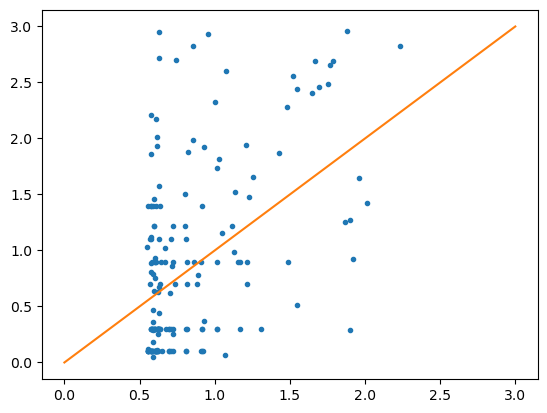

In [33]:
# D4
x_values = np.linspace(0, 3, 10)
y_values = x_values
d4_pred = best_ann.predict(X)[:,3]
plt.plot(manual_descaling(d4_pred, d4_range), manual_descaling(y[:,3], d4_range), '.')
plt.plot(x_values, y_values)
print(r2_score(d4_pred, y[:,3]))

### Predicting Optimal Parameter Sets

In [34]:
inp = np.array([[2.27355, 8.0538, 1], [1.6914, 8.345219, 2], [1.37666, 8.690144, 3], [1.27861, 9.25452, 4], [2.01798, 3.113823, 5]])

In [35]:
inp_df = pd.DataFrame(inp)
inp_df.columns = ['Disp', 'Force', 'Geom']
inp_df

,Disp,Force,Geom
0,2.27355,8.053800,1.0
1,1.69140,8.345219,2.0
2,1.37666,8.690144,3.0
3,1.27861,9.254520,4.0
4,2.01798,3.113823,5.0


In [36]:
inp_df_scaled = pd.DataFrame()
for column, col_range in inp_col_ranges.items():
    inp_df_scaled[column] = manual_scaling(inp_df[column], col_range)

In [37]:
inp_df_scaled

,Disp,Force,Geom
0,0.858065,0.721971,0.00
1,0.604957,0.763603,0.25
2,0.468113,0.812878,0.50
3,0.425483,0.893503,0.75
4,0.746948,0.016260,1.00


In [38]:
inp_scaled = np.array(inp_df_scaled)

In [39]:
best_ann.predict(inp_scaled)

array([[0.58392036, 0.2549052 , 0.38989252, 0.18130642],
       [0.5205417 , 0.3320568 , 0.33191803, 0.25642878],
       [0.5092896 , 0.29069155, 0.33182102, 0.21300238],
       [0.5086579 , 0.2749237 , 0.3354341 , 0.19482112],
       [0.4889826 , 0.25608653, 0.32388857, 0.17867382]], dtype=float32)

In [40]:
ann_pred_scaled = pd.DataFrame(best_ann.predict(inp_scaled))
ann_pred_scaled.columns = ['D1', 'D2', 'D3', 'D4']
pred = pd.DataFrame()
for column, col_range in out_col_ranges.items():
    pred[column] = manual_descaling(ann_pred_scaled[column], col_range)

In [41]:
pred

,D1,D2,D3,D4
0,1.705851,0.826676,1.199497,0.577602
1,1.523955,1.049644,1.036009,0.796208
2,1.491661,0.930099,1.035735,0.669837
3,1.489848,0.884530,1.045924,0.616929
4,1.433380,0.830090,1.013366,0.569941


### Plotting fracture loci

In [42]:
peeq_points = [0.821925, 0.805, 0.782969, 0.982276, 0.747469]
triax_points = [0.735486, 0.763, 0.775465, 0.421326, 0.154543]
lode_points = [0.271787, 0.187, 0.14384, 0.968038, 0.165233]

### G0

In [85]:
# G0
d1 = 1.71
d2 = 0.83
d3 = 1.2
d4 = 0.58

In [86]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

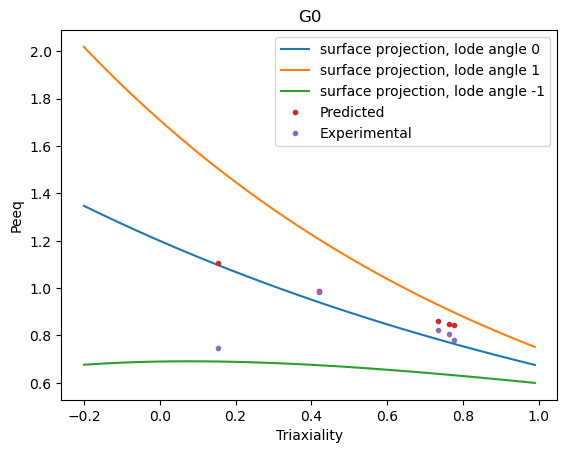

In [87]:
triax = np.arange(-0.2, 1, 0.01)
lode = 0
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * lode**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G0')
plt.legend()

In [88]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

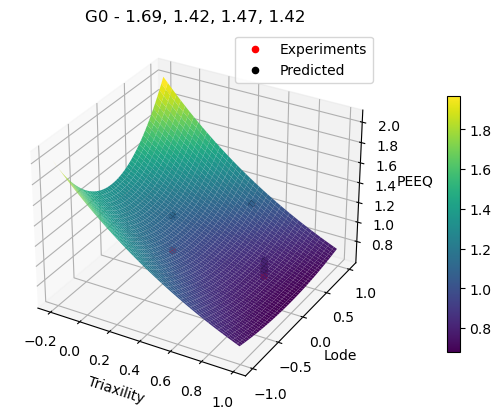

In [53]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experiments')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G0 - 1.71, ')
ax.legend()

### G1

In [80]:
# G1
d1 = 1.52
d2 = 1.05
d3 = 1.04
d4 = 0.79

In [81]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

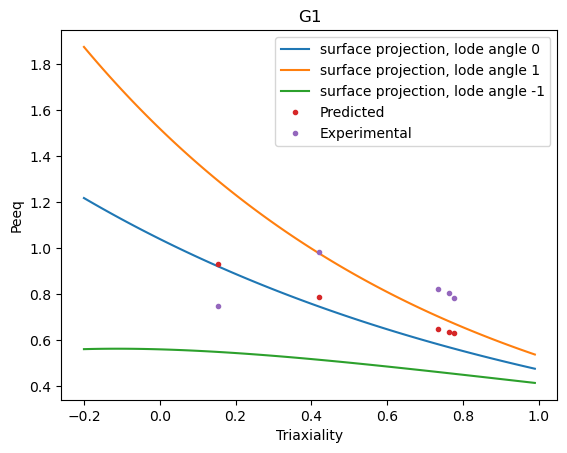

In [82]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G1')
plt.legend()

In [83]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

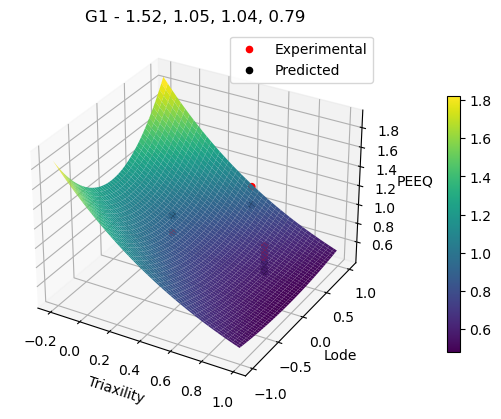

In [84]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G1 - 1.52, 1.05, 1.04, 0.79')
ax.legend()

### G2

In [76]:
d1 = 1.49
d2 = 0.93
d3 = 1.04
d4 = 0.67

In [77]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

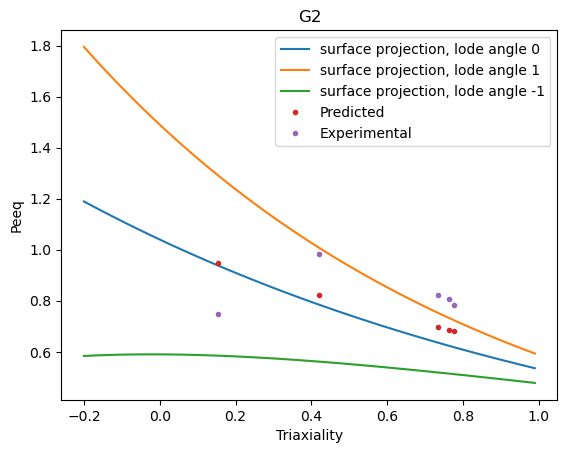

In [78]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G2')
plt.legend()

In [79]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

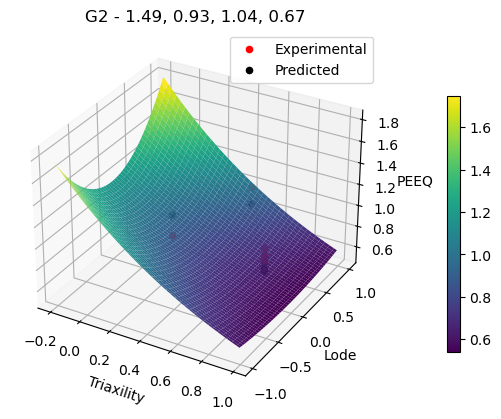

In [65]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')


ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G2 - 1.49, 0.93, 1.04, 0.67')
ax.legend()

### G3

In [66]:
d1 = 1.49
d2 = 0.88
d3 = 1.05
d4 = 0.62

In [67]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

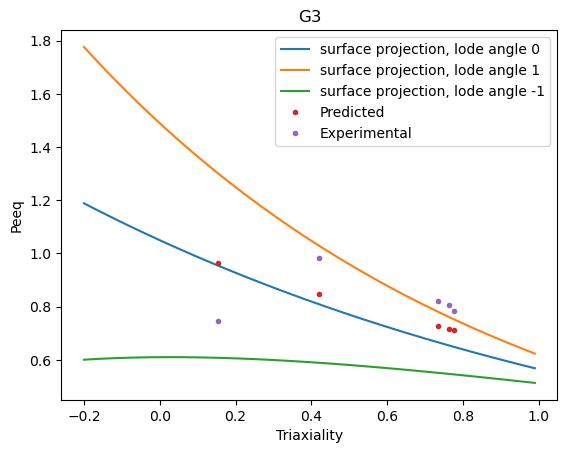

In [68]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G3')
plt.legend()

In [69]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

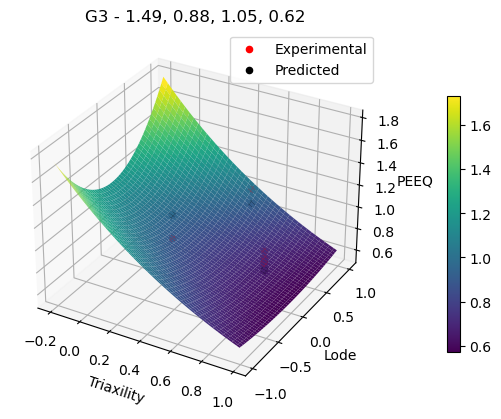

In [70]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G3 - 1.49, 0.88, 1.05, 0.62')
ax.legend()

### G4

In [71]:
d1 = 1.43
d2 = 0.83
d3 = 1.01
d4 = 0.57

In [72]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

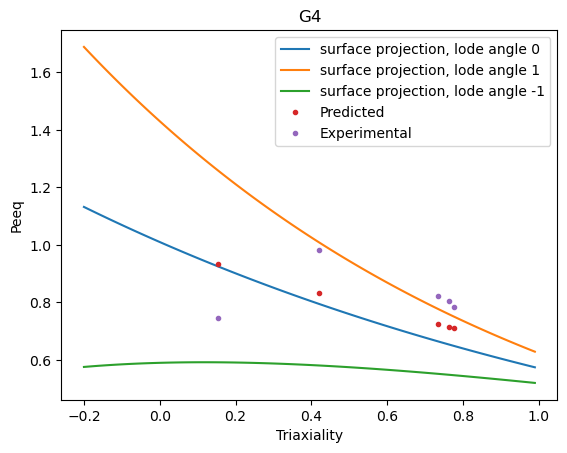

In [73]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G4')
plt.legend()

In [74]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

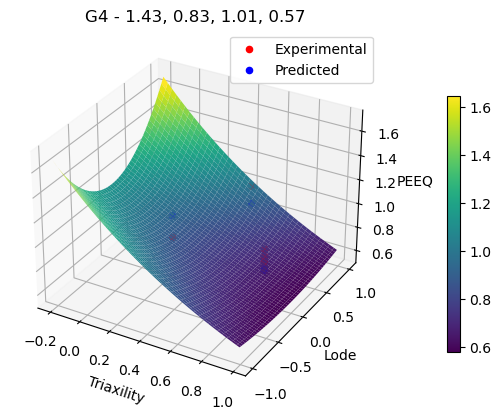

In [75]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='blue', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G4 - 1.43, 0.83, 1.01, 0.57')
ax.legend()